# Biodiversity at Scale
## Clasificación fine-grained de especies con Deep Learning — iNaturalist 2021 Mini

**Maestría de Investigación en Inteligencia Artificial — Aprendizaje Profundo (Práctica)**

---

### 1. Problema y motivación

Identificar la especie de un organismo a partir de una fotografía es un problema de
clasificación **fine-grained** a gran escala. Tres propiedades lo separan de un problema
de visión convencional:

1. **Cardinalidad.** 10,000 clases. El azar acierta el 0.01% y la capa de salida por sí
   sola aporta decenas de millones de parámetros.
2. **Separabilidad mínima entre clases.** Miles de especies comparten género. Lo que las
   distingue es un patrón local —el borde de un ala, el moteado de un pétalo— de amplitud
   muy inferior a la variación de fondo, pose e iluminación.
3. **Pocos ejemplos por clase.** 50 imágenes de entrenamiento por especie. Es poco para
   inducir desde cero un concepto visual fino.

A esto se añade que las imágenes provienen de ciencia ciudadana: no hay encuadre, escala
ni iluminación controlados, de modo que **la varianza dentro de una especie puede superar
a la varianza entre especies próximas**.

### 2. Pregunta general

> ¿Qué estrategias de arquitectura, optimización, regularización y Transfer Learning
> permiten mejorar la clasificación fine-grained de especies a gran escala?

### 3. Preguntas de investigación específicas

Este trabajo se concentra en dos preguntas sobre el uso de representaciones preentrenadas:

> **P1.** ¿El Fine-Tuning completo supera a utilizar un backbone congelado?
>
> **P2.** ¿El Partial Fine-Tuning proporciona una mejor relación entre rendimiento y
> costo computacional?

### 4. Hipótesis

**H1 — sobre P1.** El fine-tuning completo supera al backbone congelado por un margen
grande (se anticipa **más de 15 puntos de Top-1**).

*Razonamiento:* las representaciones de ImageNet están optimizadas para discriminar
categorías de nivel básico ("pájaro", "flor"). La clasificación a nivel de especie exige
rasgos de un orden de granularidad distinto. Las capas tempranas (bordes, texturas) son
reutilizables; las tardías codifican una semántica que no es la que el problema necesita.
Si la hipótesis es cierta, **congelar el backbone limita el rendimiento no por falta de
capacidad del clasificador, sino porque la información discriminante ya se perdió** antes
de llegar a él.

**H2 — sobre P2.** El fine-tuning parcial recupera **la mayor parte** de la ganancia del
fine-tuning completo a una fracción de su costo, y por tanto domina en rendimiento por
hora de GPU.

*Razonamiento:* si la adaptación necesaria se concentra en las capas tardías, descongelar
solo esas capas debería capturar casi todo el beneficio, mientras el costo de retropropagar
y de almacenar estado del optimizador crece con la profundidad descongelada.

### 5. Diseño que contrasta ambas hipótesis

Las dos preguntas se responden con **un único experimento controlado**: un barrido sobre
la profundidad de descongelamiento `k`, el número de etapas finales del backbone que se
entrenan.

| k | Condición | Corresponde a |
|---|---|---|
| 0 | backbone totalmente congelado | Experimento A — Feature Extraction |
| 1, 2, 3 | se entrenan las últimas k etapas | Experimento B — Partial Fine-Tuning |
| 4 | todo el modelo es entrenable | Experimento C — Full Fine-Tuning |

Los extremos `k=0` y `k=4` responden **P1**. La curva completa responde **P2**: en lugar de
inferir la relación costo/rendimiento de un único punto intermedio, se traza la frontera.
Se añade un **control entrenado desde cero** con el mismo presupuesto, sin el cual no se
puede separar el aporte del preentrenamiento del aporte de la arquitectura.

Cada condición se evalúa en **su propio learning rate**, elegido por un barrido corto
previo. Compararlas con un lr común mediría sobre todo la escala del paso efectivo —con el
backbone congelado solo se entrena una capa lineal, que tolera y necesita un paso mucho
mayor que un backbone preentrenado— y confundiría el efecto que se quiere aislar.

---
## Configuración del entorno

Todos los experimentos se ejecutaron en el clúster **Khipu** (UTEC) sobre una **NVIDIA A100
de 40 GB**. El notebook no entrena: carga los resultados producidos por `inat.runner` y los
analiza. Esto mantiene el notebook ejecutable en cualquier máquina y evita que el informe
dependa de celdas ejecutadas a mano en un orden particular.

In [1]:
import os, sys, json, warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))

from inat.config import DataConfig, Paths
from inat import analysis, eda, plots, registry

warnings.filterwarnings("ignore", category=UserWarning)
pd.set_option("display.width", 200, "display.max_columns", 50)
plots.use_style()

# INAT_DATA_ROOT apunta al corpus preparado (lado corto 256 px) y INAT_RESULTS a
# los JSON descargados de Khipu. Ambos se pueden sobrescribir por entorno.
PATHS = Paths(
    data_root=Path(os.environ.get("INAT_DATA_ROOT", ROOT / "data" / "inat2021")),
    results=ROOT / "results",
    figures=ROOT / "figures",
)
PATHS.figures.mkdir(exist_ok=True, parents=True)

RESULTS = analysis.load_results(PATHS.results)

# Se distingue entre tener los indices y tener las imagenes, porque casi todo el
# analisis exploratorio se calcula sobre los Parquet (45 MB) y solo las rejillas
# de ejemplos necesitan los JPEG (18 GB). Separarlo permite ejecutar el notebook
# completo en una maquina de trabajo sin copiar el corpus entero.
INDEX_OK = (PATHS.index / "train.parquet").exists()
IMAGES_OK = PATHS.images.exists() and any(PATHS.images.iterdir()) if PATHS.images.exists() else False
DATA_OK = INDEX_OK  # compatibilidad con el resto del notebook


def requiere(condicion, que, como):
    # Explica por que una celda no se ejecuta, en lugar de callar: una celda
    # guardada sin salida es indistinguible de una celda rota.
    if condicion:
        return True
    print(f"[omitido] falta {que}.")
    print(f"          {como}")
    return False


print(f"indices Parquet : {'si' if INDEX_OK else 'NO'}   ({PATHS.index})")
print(f"imagenes JPEG   : {'si' if IMAGES_OK else 'NO'}   ({PATHS.images})")
print(f"corridas cargadas: {len(RESULTS)}")
if len(RESULTS):
    print(RESULTS.groupby("group").size().to_string())
if not INDEX_OK:
    print()
    print("Para analizar sin copiar el corpus completo bastan los indices (45 MB):")
    print("  scp -r <usuario>@khipu.utec.edu.pe:~/datasets/inat2021/index data/inat2021/")
    print("O apunta INAT_DATA_ROOT al corpus preparado.")

indices Parquet : si   (/home/pedro.caycho/datasets/inat2021/index)
imagenes JPEG   : si   (/home/pedro.caycho/datasets/inat2021/images)
corridas cargadas: 41
group
arquitectura        3
baseline            4
optimizacion        5
optimizacion_lr     6
regularizacion      6
transfer_lr        14
verificacion        3


In [2]:
# Semillas, hiperparametros y presupuesto declarados en un solo lugar.
# Esta celda documenta las condiciones compartidas que hacen comparables los
# experimentos; el detalle completo de cada corrida vive en su JSON.
print(f"semillas                 : {registry.SEEDS}")
print(f"resolucion grilla        : {registry.GRID_SIZE} px   ({registry.GRID_EPOCHS} epocas)")
print(f"resolucion transfer      : {registry.TL_SIZE} px   ({registry.TL_EPOCHS} epocas)")
print(f"epocas de las sondas lr  : {registry.PROBE_EPOCHS}")
print(f"experimentos declarados  : {len(registry.all_experiments())}")
print()
print("Fases:", ", ".join(registry.PHASES))

semillas                 : (42, 43)
resolucion grilla        : 160 px   (12 epocas)
resolucion transfer      : 224 px   (15 epocas)
epocas de las sondas lr  : 3
experimentos declarados  : 54

Fases: baseline, arquitectura, optimizacion, regularizacion, transfer_lr, transfer, longtail


---
## Estado de avance del proyecto

El cómputo (`inat.runner`, sobre Slurm) y el análisis (este notebook) están separados: el
notebook lee los JSON que el runner deja, uno por corrida. Esto permite que el informe se
arme de forma incremental y que una interrupción del clúster no obligue a repetir lo ya
calculado.

La celda siguiente **compara el diseño experimental declarado en `inat.registry` contra los
resultados presentes en disco** y reporta qué bloques están completos y cuáles faltan. No es
una lista escrita a mano: se recalcula en cada ejecución, de modo que no puede quedar
desactualizada respecto de los datos.

In [3]:
from inat.registry import PHASES, EXTRA_PHASES

completadas = {p.stem for p in PATHS.results.glob("*.json")
               if not p.name.startswith("status_") and not p.name.endswith(".failed.json")}
fallidas = {p.name.replace(".failed.json", "") for p in PATHS.results.glob("*.failed.json")}

BLOQUE = {
    "baseline":        "Parte 2 - Baseline MLP",
    "arquitectura":    "Parte 3 - Arquitecturas CNN",
    "optimizacion":    "Parte 4 - Optimizacion",
    "regularizacion":  "Parte 5 - Regularizacion y ablation",
    "transfer_lr":     "Parte 6 - Sondas de learning rate",
    "transfer":        "Parte 6 - Transfer Learning (bloque principal)",
    "longtail":        "Parte 7 - Long-Tail Challenge",
}

filas, pendientes = [], {}
for fase, build in PHASES.items():
    cola = build()
    falta = [c.run_name for c in cola if c.run_name not in completadas]
    if falta:
        pendientes[fase] = falta
    filas.append({
        "Bloque del informe": BLOQUE.get(fase, fase),
        "Corridas": len(cola),
        "Completas": len(cola) - len(falta),
        "Faltan": len(falta),
        "Estado": "completo" if not falta else ("sin empezar" if len(falta) == len(cola) else "parcial"),
    })

estado = pd.DataFrame(filas)
display(estado)

tot, hechas = estado["Corridas"].sum(), estado["Completas"].sum()
print(f"Avance global: {hechas}/{tot} corridas ({100*hechas/tot:.0f}%)")
if fallidas:
    print(f"Corridas marcadas como fallidas: {sorted(fallidas)}")

pesos = list((PATHS.results / "models").glob("*.pt")) if (PATHS.results / "models").exists() else []
print(f"Pesos guardados para el analisis de errores: {len(pesos)}")

,Bloque del informe,Corridas,Completas,Faltan,Estado
0,Parte 2 - Baseline MLP,4,4,0,completo
1,Parte 3 - Arquitecturas CNN,3,3,0,completo
2,Parte 4 - Optimizacion,11,11,0,completo
3,Parte 5 - Regularizacion y ablation,6,6,0,completo
4,Parte 6 - Sondas de learning rate,15,14,1,parcial
5,Parte 6 - Transfer Learning (bloque principal),9,0,9,sin empezar
6,Parte 7 - Long-Tail Challenge,6,0,6,sin empezar


Avance global: 38/54 corridas (70%)
Pesos guardados para el analisis de errores: 0


In [4]:
# Detalle de lo que falta, para seguir armando el informe.
if pendientes:
    print("CORRIDAS PENDIENTES")
    print()
    for fase, nombres in pendientes.items():
        print(f"{BLOQUE.get(fase, fase)}  ({len(nombres)})")
        for n in nombres:
            print(f"    {n}")
        print()
    print("Para ejecutarlas:  python -m inat.runner --phase all --budget-hours 7.5")
else:
    print("Todas las corridas del diseno experimental estan completas.")

CORRIDAS PENDIENTES

Parte 6 - Sondas de learning rate  (1)
    TP_k4_0.001_tlprobe_k4_0.001_s42

Parte 6 - Transfer Learning (bloque principal)  (9)
    T0_resnet50_frozen_s42
    T0_resnet50_frozen_s43
    T1_resnet50_partial_k1_s42
    T2_resnet50_partial_k2_s42
    T2_resnet50_partial_k2_s43
    T3_resnet50_partial_k3_s42
    T4_resnet50_full_ft_s42
    T4_resnet50_full_ft_s43
    T5_resnet50_scratch_224_s42

Parte 7 - Long-Tail Challenge  (6)
    L1_balanceado_completo_s42
    L2_balanceado_equiparado_s42
    L3_longtail_sin_correccion_s42
    L4_longtail_weighted_ce_s42
    L5_longtail_weighted_sampler_s42
    L6_longtail_focal_s42

Para ejecutarlas:  python -m inat.runner --phase all --budget-hours 7.5


### Qué queda por redactar cuando lleguen los resultados

Las secciones marcadas abajo dependen de corridas que aún no existen. El código que las
produce ya está escrito y verificado; sólo esperan los datos.

| Sección | Depende de | Qué habrá que redactar |
|---|---|---|
| Parte 6 — respuesta a P1 | `T0` vs `T4` | Si el fine-tuning completo supera al backbone congelado y por cuánto |
| Parte 6 — respuesta a P2 | `T0`…`T4` | Si algún `k` intermedio domina la frontera costo/rendimiento |
| Parte 6 — aporte del preentrenamiento | `T5` (control desde cero) | Cuánto aportan los pesos de ImageNet frente a entrenar desde cero |
| Parte 7 — efecto del desbalance | `L2` vs `L3` | Cuánto del deterioro viene del desbalance y cuánto de tener menos datos |
| Parte 7 — mitigaciones | `L4`, `L5`, `L6` | Cuál estrategia recupera recall en la cola sin hundir la cabeza |
| Análisis de errores | pesos del mejor modelo | Patrones de confusión, confianza y ejemplos cualitativos |
| Discusión y conclusiones | todo lo anterior | Veredicto sobre H1 y H2 |

---
# Parte 1 — Exploración y preparación del dataset

In [5]:
SUMMARY = None
if requiere(INDEX_OK, "los indices Parquet",
            "scp -r <usuario>@khipu.utec.edu.pe:~/datasets/inat2021/index data/inat2021/"):
    SUMMARY = eda.summarize(PATHS)
    display(SUMMARY.as_frame())

,Caracteristica,Valor
0,Imagenes de entrenamiento,"500,000"
1,Imagenes de validacion,"100,000"
2,Especies,"10,000"
3,Imagenes por especie (train),50-50
4,Imagenes por especie (val),10-10
5,Taxones distintos - kingdom,3
6,Taxones distintos - phylum,13
7,Taxones distintos - class,51
8,Taxones distintos - order,273
9,Taxones distintos - family,"1,103"


,especies
class,
Magnoliopsida,3295
Insecta,2526
Aves,1486
Liliopsida,674
Reptilia,313
Mammalia,246
Agaricomycetes,245
Actinopterygii,183
Amphibia,170


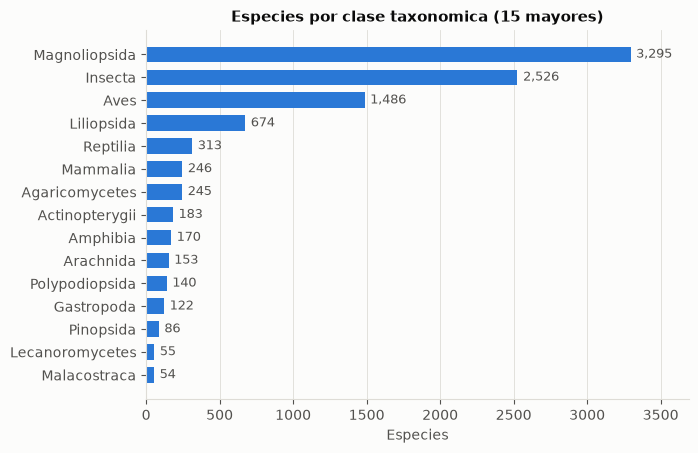

In [6]:
# Distribucion de especies por grupo taxonomico. El corpus esta balanceado a
# nivel de especie, pero no a nivel de grupo: la mitad de las especies son
# plantas e insectos.
if requiere(INDEX_OK, "los indices Parquet",
            "scp -r <usuario>@khipu.utec.edu.pe:~/datasets/inat2021/index data/inat2021/"):
    por_clase = eda.species_per_rank(PATHS, "class")
    display(por_clase.head(12).to_frame("especies"))
    plots.plot_taxonomic_distribution(
        por_clase.head(15), "Especies por clase taxonomica (15 mayores)",
        path=PATHS.figures / "01_taxonomia.png")
    plt.show()

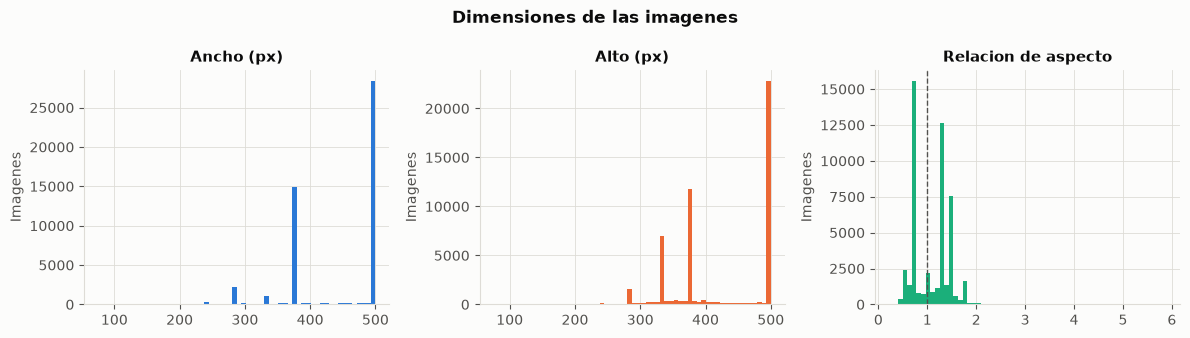

In [7]:
# Dimensiones de las imagenes: determinan cuanta senal fina sobrevive al
# reescalado a la resolucion de entrada de la red.
if requiere(INDEX_OK, "los indices Parquet",
            "scp -r <usuario>@khipu.utec.edu.pe:~/datasets/inat2021/index data/inat2021/"):
    plots.plot_image_dimensions(SUMMARY.dimensions, path=PATHS.figures / "02_dimensiones.png")
    plt.show()

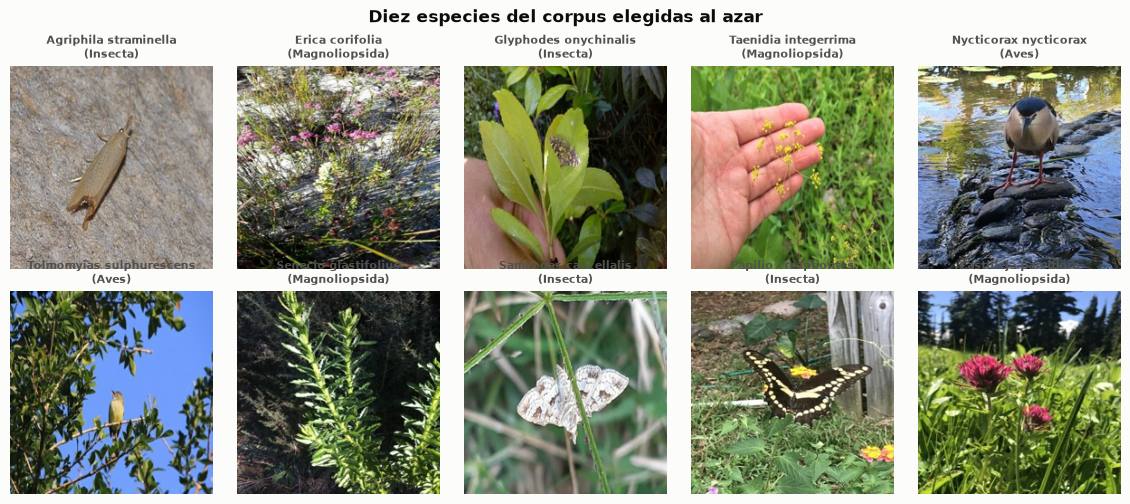

In [8]:
# Muestra aleatoria de especies (semilla fija: la seleccion no es manual).
if requiere(IMAGES_OK, "las imagenes JPEG",
            "apunta INAT_DATA_ROOT al corpus preparado (18 GB) o ejecuta este notebook en el cluster"):
    imgs, caps = eda.sample_species_grid(PATHS, n_species=10, seed=42)
    plots.plot_image_grid(imgs, caps, ncols=5,
                          title="Diez especies del corpus elegidas al azar",
                          path=PATHS.figures / "03_muestra.png")
    plt.show()

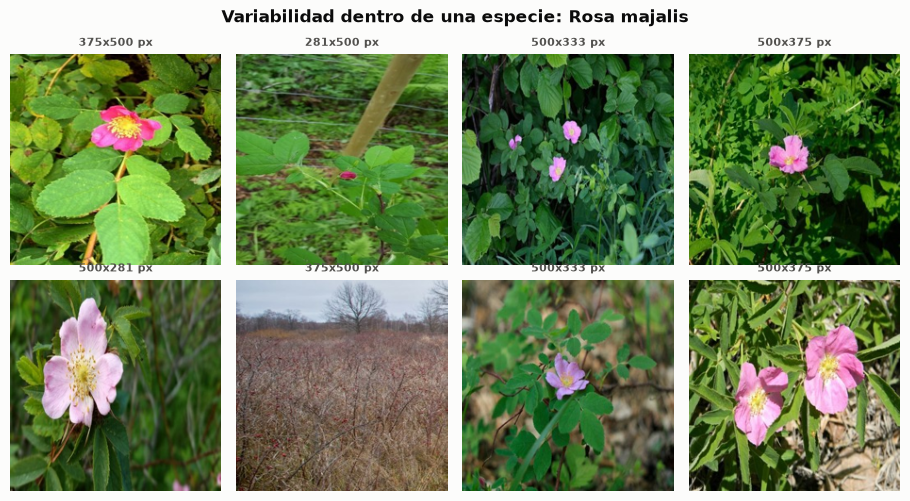

In [9]:
# Variabilidad DENTRO de una misma especie.
if requiere(IMAGES_OK, "las imagenes JPEG",
            "apunta INAT_DATA_ROOT al corpus preparado (18 GB) o ejecuta este notebook en el cluster"):
    imgs, caps, titulo = eda.intra_class_grid(PATHS, n=8, seed=7)
    plots.plot_image_grid(imgs, caps, ncols=4, title=titulo,
                          path=PATHS.figures / "04_intra_clase.png")
    plt.show()

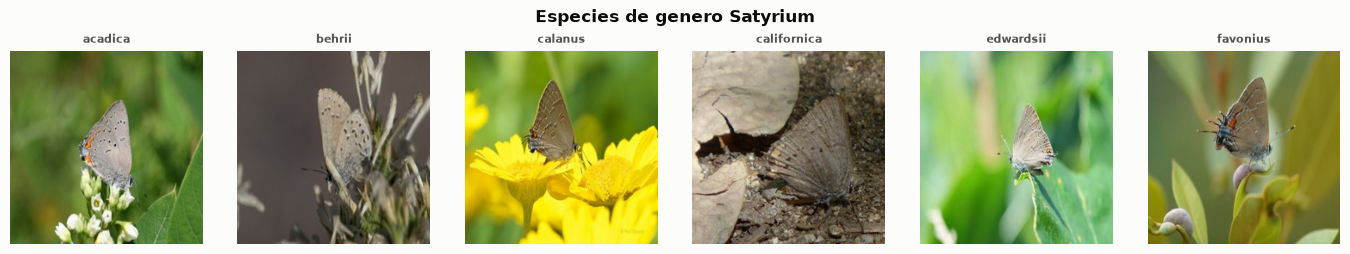

In [10]:
# Similitud ENTRE especies distintas del mismo genero: el nucleo del problema
# fine-grained. Se baja a un rango mas grueso si el corpus cargado no tiene
# especies congenericas (ocurre en el subset de desarrollo, no en el completo).
if requiere(IMAGES_OK, "las imagenes JPEG",
            "apunta INAT_DATA_ROOT al corpus preparado (18 GB) o ejecuta este notebook en el cluster"):
    for rango in ("genus", "family", "order", "class"):
        try:
            imgs, caps, titulo = eda.inter_class_grid(PATHS, rank=rango, n_species=6, seed=3)
            break
        except ValueError:
            continue
    else:
        imgs, caps, titulo = [], [], "sin taxones comparables en este corpus"
    plots.plot_image_grid(imgs, caps, ncols=6, title=titulo,
                          path=PATHS.figures / "05_inter_clase.png")
    plt.show()

### Por qué este problema es difícil desde la perspectiva del Deep Learning

Las dos rejillas anteriores muestran el obstáculo central de forma directa: **la variación
dentro de una especie es visualmente mayor que la variación entre especies del mismo
género**. Un clasificador entrenado con la señal habitual —formas globales, color
dominante, contexto— aprende exactamente el eje equivocado.

La tabla siguiente liga cada dificultad a una cifra concreta del corpus, para que la
discusión descanse en los datos y no en generalidades sobre clasificación fine-grained.

In [11]:
if requiere(INDEX_OK, "los indices Parquet",
            "scp -r <usuario>@khipu.utec.edu.pe:~/datasets/inat2021/index data/inat2021/"):
    display(eda.difficulty_notes(SUMMARY, PATHS))

,Dificultad,Evidencia en el corpus,Consecuencia
0,Numero de clases,"10,000 especies",La capa de salida domina el conteo de parametr...
1,Ejemplos por clase,50 imagenes de entrenamiento,Muy pocas para aprender desde cero un concepto...
2,Similitud entre clases,"1,726 generos con mas de una especie (6,842 es...",Especies del mismo genero comparten morfologia...
3,Variabilidad dentro de la clase,"pose, iluminacion, escala y fondo libres","Son fotografias de ciencia ciudadana, no tomas..."
4,Resolucion,mediana 500x403 px,"Al reescalar a 160-224 px, los rasgos diagnost..."
5,Desbalance taxonomico,6 rangos anotados,Los grupos taxonomicos no estan igualmente rep...


### Pipeline de datos

Las anotaciones vienen en JSON estilo COCO (208 MB para entrenamiento). Leerlas en cada
corrida costaría segundos que no aportan nada, así que se convierten **una sola vez** a
tablas Parquet (`inat.data.build_index`).

El corpus original son ~50 GB de JPEG con lado mayor de 500 px. Entrenar sobre ellos
significa decodificar 600,000 imágenes grandes por época, lo que satura la CPU y deja la
A100 esperando datos. `scripts/prepare_data.py` genera una vez una copia con **lado corto
fijo en 256 px** (suficiente para recortes de hasta 224 px), que ocupa ~13 GB y se
decodifica varias veces más rápido. Es la única transformación irreversible del pipeline y
se aplica antes de cualquier experimento, de modo que **todos los modelos ven exactamente
los mismos píxeles**.

**Garantías de reproducibilidad.** Una semilla única por experimento alimenta la
inicialización de pesos, el orden del `DataLoader`, la augmentation y el muestreo de
clases (`inat.seeding`). Los workers reciben semillas derivadas y deterministas. El
escenario long-tail se construye **íntegramente por código** a partir de una semilla
declarada: no hay selección manual de archivos en ninguna etapa. Cada corrida serializa su
configuración completa junto a sus resultados, de modo que cada fila de la tabla final es
trazable hasta sus hiperparámetros exactos.

**El conjunto de validación no se usa nunca para entrenar.** Se usa para early stopping y
para seleccionar el learning rate de cada condición; esa elección se documenta como parte
del diseño y se aplica por igual a todas las condiciones comparadas.

In [12]:
# Verificacion del escenario balanceado y de los DataLoaders.
if requiere(INDEX_OK, "los indices Parquet",
            "scp -r <usuario>@khipu.utec.edu.pe:~/datasets/inat2021/index data/inat2021/"):
    esc = eda.summarize(PATHS)
    print(f"entrenamiento : {esc.n_train:,} imagenes")
    print(f"validacion    : {esc.n_val:,} imagenes")
    print(f"especies      : {esc.n_species:,}")
    print(f"img/especie   : {esc.images_per_species_train.min()}"
          f"-{esc.images_per_species_train.max()} (train), "
          f"{esc.images_per_species_val.min()}-{esc.images_per_species_val.max()} (val)")

entrenamiento : 500,000 imagenes
validacion    : 100,000 imagenes
especies      : 10,000
img/especie   : 50-50 (train), 10-10 (val)


---
# Parte 2 — Baseline con Perceptrón Multicapa

El objetivo de este bloque **no es obtener el mejor rendimiento posible**, sino establecer
un piso y demostrar experimentalmente las limitaciones de una arquitectura completamente
conectada para procesar imágenes.

### Decisiones y justificación

| Decisión | Valor | Justificación |
|---|---|---|
| Resolución | 32, 48, 64 px | Barrido deliberado: el MLP vectoriza la imagen, así que la resolución controla directamente el tamaño de la primera capa. |
| Capas ocultas | 2 (2048, 1024) | Suficiente profundidad para que el fallo sea atribuible a la ausencia de estructura convolucional, no a falta de capacidad. |
| Activación | ReLU | No satura para activaciones positivas; evita el gradiente desvanecido de sigmoide/tanh en redes densas profundas. |
| Inicialización | He (Kaiming normal) | Derivada para ReLU: preserva la varianza de la activación capa a capa. |
| Normalización | BatchNorm1d | Con 12,288 entradas crudas las escalas por unidad son muy dispares; se ablaciona en B4. |
| Pérdida | Cross-entropy | Clasificación multiclase de etiqueta única. |
| Batch size | 512 | El modelo es barato por imagen; lotes grandes aprovechan la GPU y estabilizan BatchNorm. |
| Optimizador | Adam (lr 1e-3) | Una red densa sobre píxeles crudos tiene gradientes muy mal escalados entre capas; SGD con un único lr global converge notablemente peor. |

### El costo de vectorizar la imagen

Al aplanar una imagen se pierden dos propiedades que una CNN explota por construcción:

- **Localidad.** Píxeles vecinos dejan de ser vecinos; cada unidad oculta ve todos los
  píxeles con pesos independientes y debe *aprender* que la proximidad importa.
- **Invarianza a traslación.** Un mismo rasgo desplazado unos píxeles activa un conjunto
  de pesos completamente distinto. El MLP tiene que aprender cada rasgo en cada posición.

El costo es además cuantificable: la primera capa tiene `3·s²·h` pesos, de modo que
**duplicar el lado de la imagen cuadruplica esa capa**.

In [13]:
# Crecimiento del numero de parametros con la resolucion de entrada.
from inat.config import ModelConfig
from inat.models import build_model, count_parameters

filas = []
for size in (32, 48, 64, 96, 128):
    modelo = build_model(ModelConfig(arch="mlp", mlp_hidden=(2048, 1024)), 10_000, size)
    primera = modelo.net[1].weight.numel()
    total = count_parameters(modelo).total
    filas.append({"Resolucion": f"{size}x{size}",
                  "Entradas": 3 * size * size,
                  "Primera capa (M)": primera / 1e6,
                  "Total (M)": total / 1e6,
                  "Primera capa / total": primera / total})
tabla_mlp = pd.DataFrame(filas).round(3)
display(tabla_mlp)
print("\nAl pasar de 32 a 64 px la primera capa se multiplica por "
      f"{filas[2]['Primera capa (M)'] / filas[0]['Primera capa (M)']:.1f}")

,Resolucion,Entradas,Primera capa (M),Total (M),Primera capa / total
0,32x32,3072,6.291,18.648,0.337
1,48x48,6912,14.156,26.512,0.534
2,64x64,12288,25.166,37.522,0.671
3,96x96,27648,56.623,68.979,0.821
4,128x128,49152,100.663,113.020,0.891



Al pasar de 32 a 64 px la primera capa se multiplica por 4.0


,ID,Modelo,Bloque,Arquitectura,Resolucion,Optimizador,LR,Augmentation,Preentrenado,Congelamiento,Escenario,Top-1,Top-5,Macro-F1,Weighted-F1,Entrenables (M),GPU-h,Epocas
3,B1,mlp_32px,baseline,mlp,32,adam,0.001,flip,False,none,balanced,1.95,5.77,1.36,1.36,18.65,0.58,10
4,B2,mlp_48px,baseline,mlp,48,adam,0.001,flip,False,none,balanced,1.86,5.52,1.27,1.27,26.51,0.21,10
5,B3,mlp_64px,baseline,mlp,64,adam,0.001,flip,False,none,balanced,1.77,5.28,1.18,1.18,37.52,0.22,10
6,B4,mlp_64px_sin_bn,baseline,mlp,64,adam,0.001,flip,False,none,balanced,0.40,1.69,0.13,0.13,37.52,0.22,10


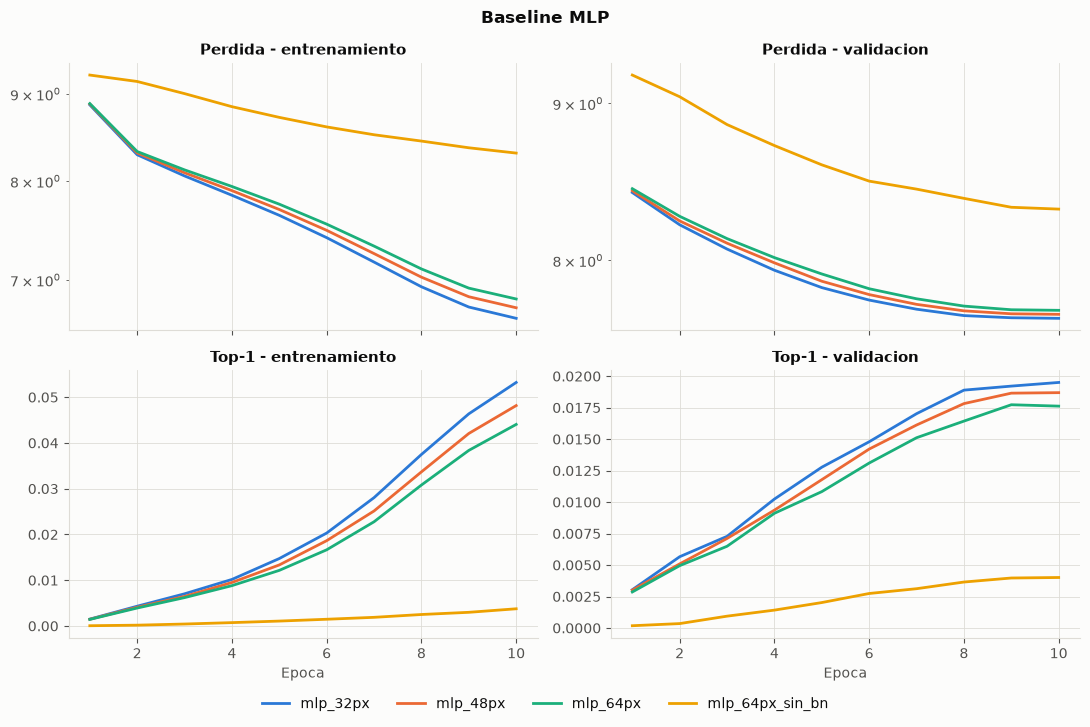

In [14]:
# Resultados del baseline.
BASE = RESULTS[RESULTS["group"] == "baseline"]
if len(BASE):
    display(analysis.final_table(BASE))
    hist = analysis.history_frame(PATHS.results, BASE["run_name"].tolist())
    etiquetas = dict(zip(BASE["run_name"], BASE["name"]))
    plots.plot_learning_curves(hist, etiquetas, "Baseline MLP",
                               path=PATHS.figures / "06_mlp_curvas.png")
    plt.show()
else:
    print("Pendiente: fase 'baseline'.")

*(Lectura de los resultados: ver la discusión al final del bloque, una vez cargadas las
corridas.)*

### Limitaciones del MLP frente a una CNN

| Aspecto | MLP | CNN |
|---|---|---|
| Parámetros de la primera capa | `3·s²·h`, crece con `s²` | `k²·c_in·c_out`, **independiente de `s`** |
| Localidad | debe aprenderse | impuesta por el kernel |
| Invarianza a traslación | no existe | por compartición de pesos |
| Jerarquía de rasgos | implícita y costosa | explícita por apilamiento |
| Escalado de resolución | prohibitivo | lineal en área |

---
# Parte 3 — Arquitecturas convolucionales modernas

Se comparan tres arquitecturas bajo **condiciones idénticas** (misma resolución, mismas
épocas, mismo optimizador, misma augmentation, inicialización aleatoria). La única variable
es la arquitectura.

### Arquitecturas seleccionadas

**ResNet-50** — *Idea principal:* aprender residuos `F(x)+x` en lugar de la función
completa. *Problema que resuelve:* la degradación al aumentar la profundidad; la conexión
identidad da al gradiente un camino sin atenuación hasta las capas tempranas.
*Componentes:* bloques *bottleneck* (1×1 → 3×3 → 1×1) con BatchNorm, en cuatro etapas de
resolución decreciente. *Complejidad:* ~25.6 M parámetros, ~4.1 GFLOPs a 224 px.
*Por qué aquí:* es la referencia estándar en clasificación fine-grained y el backbone con
pesos de ImageNet mejor caracterizados, lo que lo hace la base natural del bloque de
transfer learning.

**EfficientNet-B0** — *Idea principal:* escalado compuesto, que ajusta profundidad, anchura
y resolución con una relación fija en lugar de una sola dimensión. *Problema que resuelve:*
el escalado por una sola dimensión satura rápido. *Componentes:* bloques MBConv
(convolución invertida con *depthwise separable*) y módulos *squeeze-and-excitation* que
reponderan canales. *Complejidad:* ~5.3 M parámetros, ~0.39 GFLOPs. *Por qué aquí:* prueba
si una arquitectura con cinco veces menos parámetros sostiene el rendimiento, y su
atención por canal es a priori favorable cuando la señal discriminante es una textura
local.

**MobileNetV3-Large** — *Idea principal:* diseño orientado a latencia, con bloques
*depthwise separable*, activación *hard-swish* y una parte de la topología encontrada por
búsqueda de arquitectura. *Problema que resuelve:* operar con un presupuesto de cómputo
reducido. *Complejidad:* ~5.5 M parámetros, ~0.22 GFLOPs. *Por qué aquí:* ancla el extremo
barato de la curva de costo. Sin él la comparación tendría solo un eje de exactitud; con él
puede leerse como una frontera costo/rendimiento.

,ID,Modelo,Bloque,Arquitectura,Resolucion,Optimizador,LR,Augmentation,Preentrenado,Congelamiento,Escenario,Top-1,Top-5,Macro-F1,Weighted-F1,Entrenables (M),GPU-h,Epocas
0,A1,resnet50_scratch,arquitectura,resnet50,160,sgd_momentum,0.1,rrc+flip,False,none,balanced,37.15,60.12,36.26,36.26,44.00,0.61,12
1,A2,efficientnet_b0_scratch,arquitectura,efficientnet_b0,160,sgd_momentum,0.1,rrc+flip,False,none,balanced,33.97,56.65,32.83,32.83,16.82,0.53,12
2,A3,mobilenet_v3_large_scratch,arquitectura,mobilenet_v3_large,160,sgd_momentum,0.1,rrc+flip,False,none,balanced,30.74,52.73,29.80,29.80,17.01,0.41,12


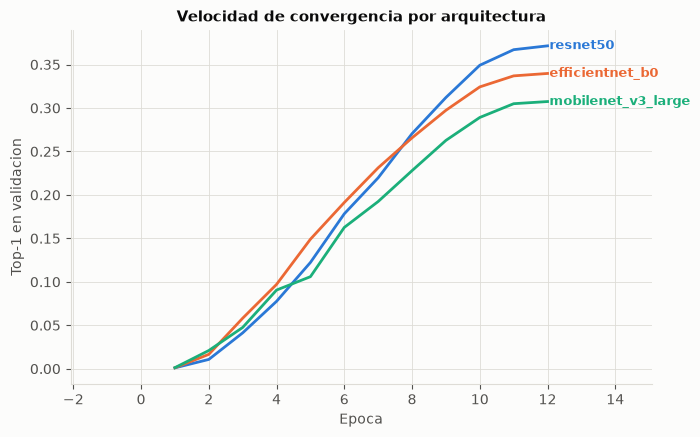

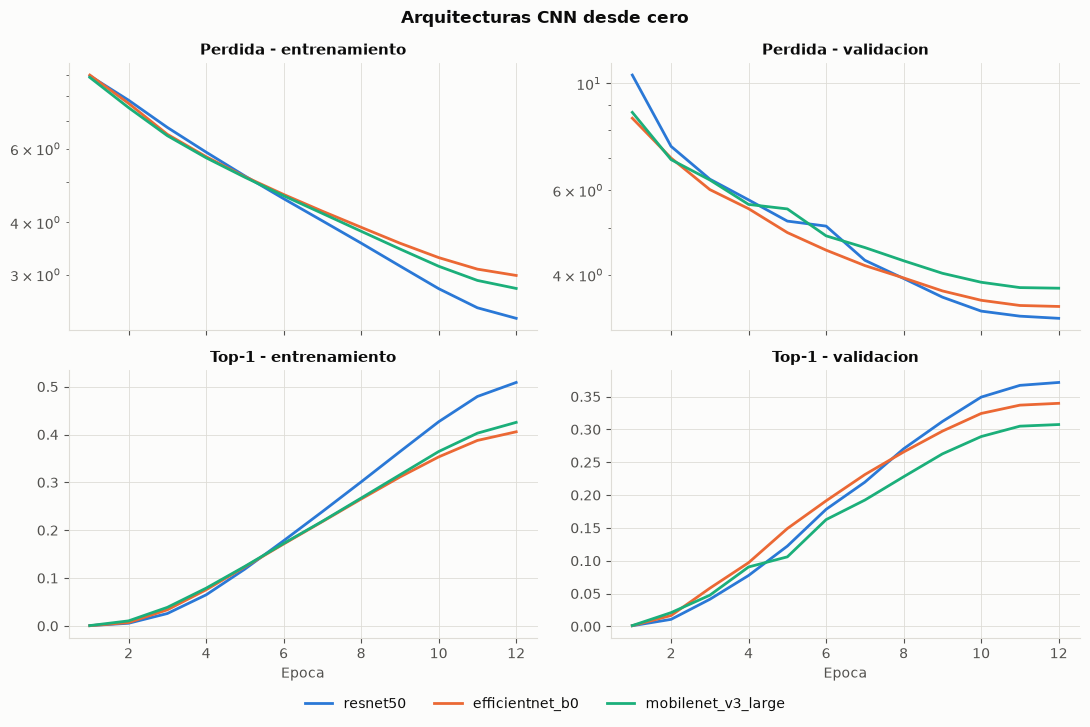

In [15]:
ARQ = RESULTS[RESULTS["group"] == "arquitectura"]
if len(ARQ):
    display(analysis.final_table(ARQ))
    hist = analysis.history_frame(PATHS.results, ARQ["run_name"].tolist())
    etiquetas = dict(zip(ARQ["run_name"], ARQ["arch"]))
    plots.plot_convergence(hist, etiquetas,
                           title="Velocidad de convergencia por arquitectura",
                           path=PATHS.figures / "07_arq_convergencia.png")
    plt.show()
    plots.plot_learning_curves(hist, etiquetas, "Arquitecturas CNN desde cero",
                               path=PATHS.figures / "08_arq_curvas.png")
    plt.show()
else:
    print("Pendiente: fase 'arquitectura'.")

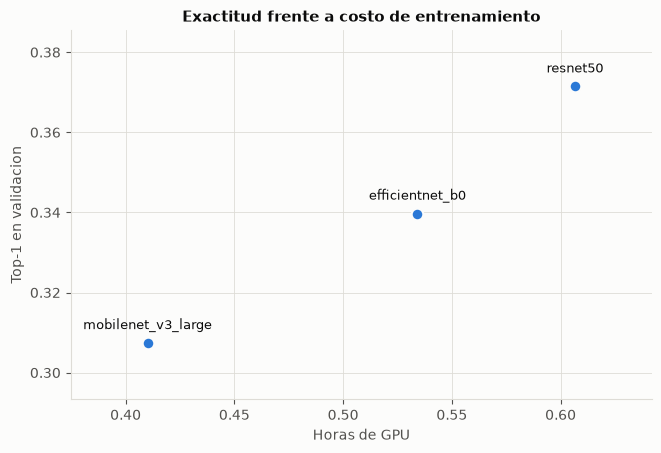

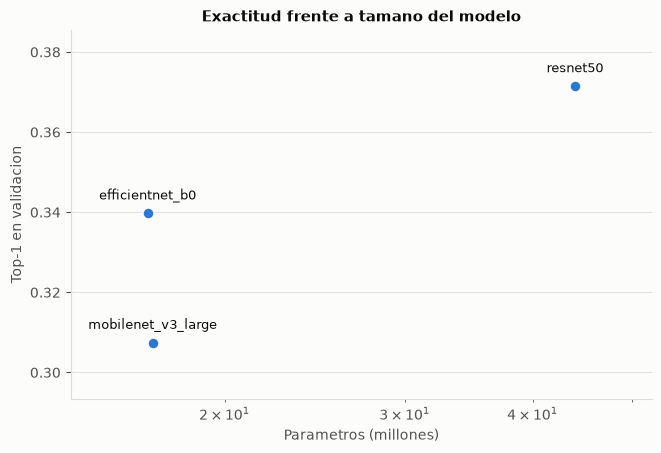

In [16]:
# Eje de eficiencia: exactitud frente a costo y a tamano del modelo.
if len(ARQ):
    frente = ARQ.assign(etiqueta=ARQ["arch"])
    plots.plot_efficiency_scatter(
        frente, "gpu_hours", "top1", "etiqueta",
        "Horas de GPU", "Top-1 en validacion",
        "Exactitud frente a costo de entrenamiento",
        path=PATHS.figures / "09_arq_costo.png")
    plt.show()
    plots.plot_efficiency_scatter(
        frente, "params_total_m", "top1", "etiqueta",
        "Parametros (millones)", "Top-1 en validacion",
        "Exactitud frente a tamano del modelo", logx=True,
        path=PATHS.figures / "10_arq_params.png")
    plt.show()

---
# Parte 4 — Optimización

Se comparan cinco optimizadores sobre ResNet-50, manteniendo constantes arquitectura,
resolución, épocas, augmentation y schedule.

**Una advertencia metodológica.** Comparar SGD y Adam con el *mismo* learning rate no
compara algoritmos: compara escalas de paso. Adam normaliza el gradiente por una estimación
de su segundo momento, de modo que su paso efectivo es de un orden de magnitud distinto al
de SGD. Cada optimizador se evalúa por tanto en su lr de referencia habitual, y el barrido
corto de la celda siguiente documenta explícitamente esa sensibilidad en lugar de ocultarla.

,ID,Modelo,Bloque,Arquitectura,Resolucion,Optimizador,LR,Augmentation,Preentrenado,Congelamiento,Escenario,Top-1,Top-5,Macro-F1,Weighted-F1,Entrenables (M),GPU-h,Epocas
7,O1,resnet50_sgd,optimizacion,resnet50,160,sgd,0.100,rrc+flip,False,none,balanced,11.88,26.84,10.10,10.10,44.0,0.59,12
8,O2,resnet50_sgd_momentum,optimizacion,resnet50,160,sgd_momentum,0.100,rrc+flip,False,none,balanced,37.15,60.12,36.26,36.26,44.0,0.59,12
9,O3,resnet50_adam,optimizacion,resnet50,160,adam,0.001,rrc+flip,False,none,balanced,37.75,60.72,36.93,36.93,44.0,0.60,12
10,O4,resnet50_adamw,optimizacion,resnet50,160,adamw,0.001,rrc+flip,False,none,balanced,35.45,57.22,35.01,35.01,44.0,0.60,12
11,O5,resnet50_rmsprop,optimizacion,resnet50,160,rmsprop,0.001,rrc+flip,False,none,balanced,5.20,14.15,3.77,3.77,44.0,0.61,12


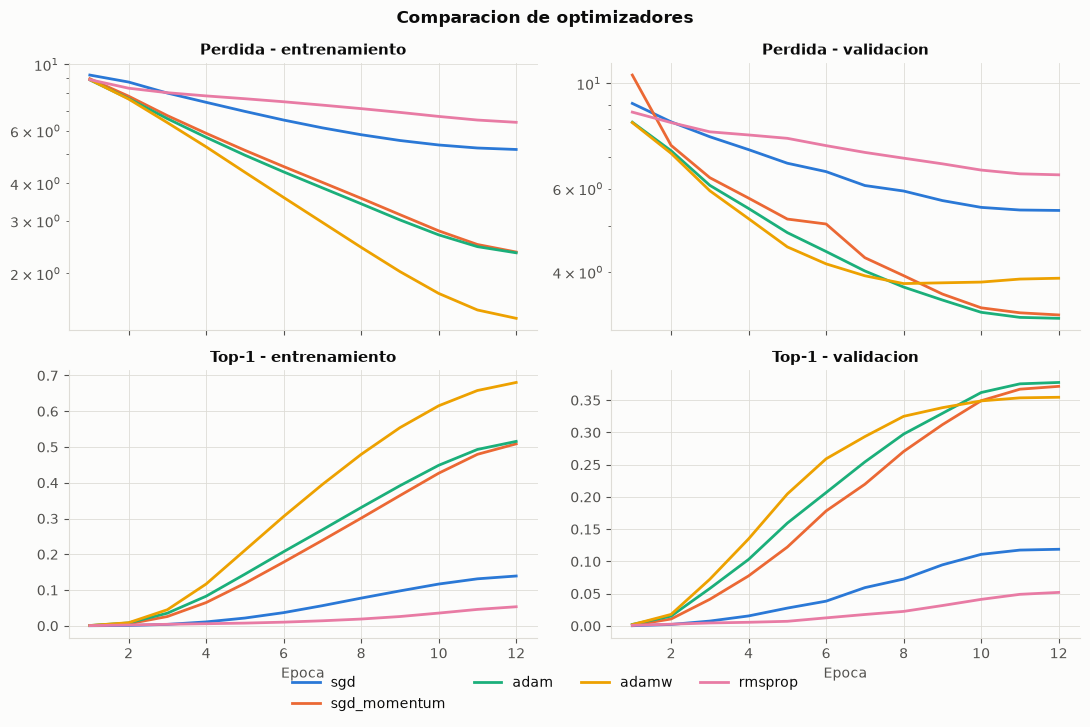

In [17]:
OPT = RESULTS[RESULTS["group"] == "optimizacion"]
if len(OPT):
    display(analysis.final_table(OPT))
    hist = analysis.history_frame(PATHS.results, OPT["run_name"].tolist())
    etiquetas = dict(zip(OPT["run_name"], OPT["optimizer"]))
    plots.plot_learning_curves(hist, etiquetas, "Comparacion de optimizadores",
                               path=PATHS.figures / "11_opt_curvas.png")
    plt.show()
else:
    print("Pendiente: fase 'optimizacion'.")

,optimizer,lr,top1,top5,macro_f1,val_loss
0,adam,0.0001,0.01815,0.06054,0.009984,7.272774
1,adam,0.0010,0.06888,0.17836,0.051508,6.046615
2,adam,0.0050,0.02551,0.08145,0.014522,6.973677
3,sgd_momentum,0.0100,0.00449,0.01764,0.001198,8.074294
4,sgd_momentum,0.1000,0.02751,0.08440,0.015864,6.900599
5,sgd_momentum,0.4000,0.01627,0.05551,0.008291,7.297083


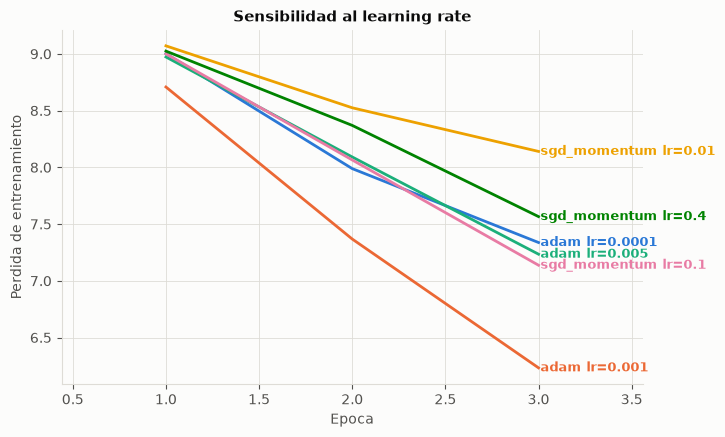

In [18]:
# Sensibilidad al learning rate (sondas de pocas epocas).
LR = RESULTS[RESULTS["group"] == "optimizacion_lr"]
if len(LR):
    tabla = (LR[["optimizer", "lr", "top1", "top5", "macro_f1", "val_loss"]]
             .sort_values(["optimizer", "lr"]).reset_index(drop=True))
    display(tabla)
    hist = analysis.history_frame(PATHS.results, LR["run_name"].tolist())
    etiquetas = {r: f"{o} lr={l:g}" for r, o, l in zip(LR["run_name"], LR["optimizer"], LR["lr"])}
    plots.plot_convergence(hist, etiquetas, metric="train_loss",
                           ylabel="Perdida de entrenamiento",
                           title="Sensibilidad al learning rate",
                           path=PATHS.figures / "12_lr_sensibilidad.png")
    plt.show()
else:
    print("Pendiente: sondas de learning rate.")

### Por qué los optimizadores se comportan de forma distinta

- **SGD puro** usa el gradiente sin memoria. En una superficie con curvatura muy desigual
  —lo habitual en redes profundas— oscila en las direcciones de curvatura alta y avanza
  despacio en las de curvatura baja.
- **SGD con momentum** acumula un promedio exponencial del gradiente. Eso cancela las
  oscilaciones y acelera las direcciones consistentes: en la práctica es lo que hace
  utilizable un lr alto.
- **Adam** mantiene estimaciones del primer y segundo momento y normaliza cada coordenada
  por la segunda. Converge rápido al principio porque adapta el paso por parámetro. Su
  contrapartida en clasificación es conocida: tiende a generalizar algo peor que SGD con
  momentum bien ajustado, y la brecha entre entrenamiento y validación suele ser mayor.
- **AdamW** separa el weight decay del gradiente adaptativo. En Adam el decay se mezcla con
  la normalización y su efecto real varía por parámetro; desacoplarlo lo convierte otra vez
  en una regularización uniforme.
- **RMSProp** es Adam sin corrección de sesgo del primer momento; su comportamiento
  temprano es más errático con el mismo lr.

La lectura relevante no es cuál alcanza mayor Accuracy, sino **cómo se separan las curvas
de entrenamiento y validación**: es ahí donde la capacidad de generalización se distingue
de la velocidad de convergencia.

---
# Parte 5 — Regularización, Data Augmentation y Early Stopping

### Early Stopping

| Elemento | Decisión |
|---|---|
| Métrica monitoreada | Top-1 en validación (Macro-F1 en el bloque long-tail, donde el Top-1 está dominado por las clases frecuentes) |
| Modo | maximizar |
| Paciencia | 4 épocas |
| Criterio de mejora | incremento absoluto > 1e-4 |
| Recuperación | se conservan los pesos de la mejor época y se restauran antes de la evaluación final |

Conservar la mejor época y no la última importa: el modelo que se reporta es el que mejor
generalizó, no el que más entrenó.

### Ablation study

Escalera incremental sobre ResNet-50 desde cero: cada fila añade **un** componente, de modo
que la diferencia entre filas consecutivas sea atribuible a ese componente.

| Exp. | Augmentation | Dropout | Weight decay |
|---|---|---|---|
| R1 | no | no | no |
| R2 | sí (crop + flip) | no | no |
| R3 | sí | sí | no |
| R4 | sí | sí | sí |

R5 y R6 aíslan dos transformaciones cuyo efecto no es obvio en un problema fine-grained.
BatchNorm se ablaciona por separado en el baseline MLP (B3 vs B4), donde la arquitectura es
controlable: las CNN de torchvision la traen incrustada y quitarla cambiaría la red entera.

,Exp.,Configuracion,Augmentation,Dropout,Weight decay,Top-1,Macro-F1,Brecha train-val,Delta vs anterior
0,R1,sin_regularizacion,ninguna,no,no,25.45,25.09,41.98,NaN
1,R2,mas_augmentation,rrc+flip,no,no,33.40,32.53,13.83,7.95
2,R3,mas_dropout,rrc+flip,si,no,31.96,30.97,6.36,-1.44
3,R4,mas_weight_decay,rrc+flip,si,si,39.01,37.63,2.54,7.05
4,R5,color_jitter_fuerte,rrc+flip+jitter0.4,si,si,32.81,31.04,-0.32,-6.20
5,R6,random_erasing,rrc+flip+erase0.25,si,si,37.40,35.90,0.37,4.59


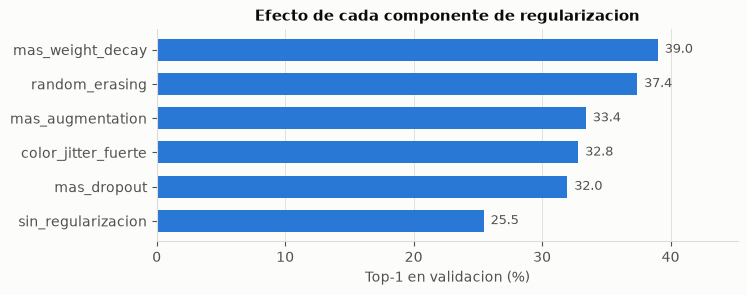

In [19]:
REG = RESULTS[RESULTS["group"] == "regularizacion"]
if len(REG):
    display(analysis.ablation_table(RESULTS))
    plots.plot_metric_bars(
        REG.assign(top1_pct=REG["top1"] * 100), "name", "top1_pct",
        "Efecto de cada componente de regularizacion", "Top-1 en validacion (%)",
        path=PATHS.figures / "13_ablation.png")
    plt.show()
else:
    print("Pendiente: fase 'regularizacion'.")

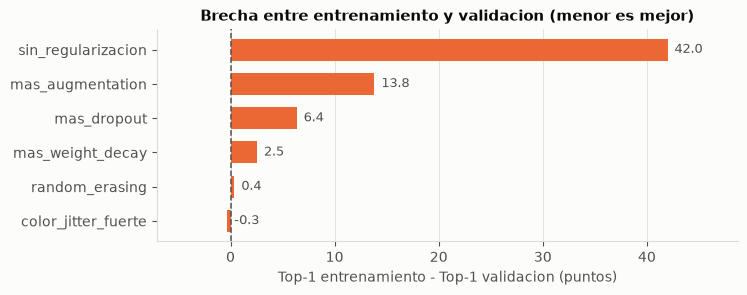

In [20]:
# Sobreajuste: brecha entre entrenamiento y validacion en la mejor epoca.
if len(REG):
    brecha = REG.assign(gap_pct=REG["train_val_gap"] * 100)
    plots.plot_metric_bars(
        brecha, "name", "gap_pct",
        "Brecha entre entrenamiento y validacion (menor es mejor)",
        "Top-1 entrenamiento - Top-1 validacion (puntos)",
        color_idx=1, baseline=0.0, path=PATHS.figures / "14_brecha.png")
    plt.show()

,exp_id,name,top1,top5,macro_f1,epochs_run,best_epoch,train_val_gap
5,B3,mlp_64px,0.01773,0.05283,0.011832,10,9,0.020636
6,B4,mlp_64px_sin_bn,0.00397,0.01692,0.001320,10,9,-0.000990


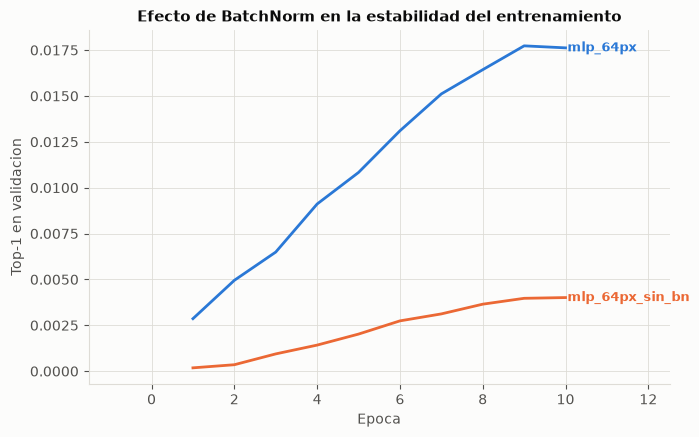

In [21]:
# BatchNorm aislado en el baseline denso.
BN = RESULTS[RESULTS["exp_id"].isin(["B3", "B4"])]
if len(BN) == 2:
    display(BN[["exp_id", "name", "top1", "top5", "macro_f1", "epochs_run",
                "best_epoch", "train_val_gap"]])
    hist = analysis.history_frame(PATHS.results, BN["run_name"].tolist())
    plots.plot_convergence(hist, dict(zip(BN["run_name"], BN["name"])),
                           title="Efecto de BatchNorm en la estabilidad del entrenamiento",
                           path=PATHS.figures / "15_batchnorm.png")
    plt.show()

### ¿Puede la Data Augmentation destruir rasgos diagnósticos?

Esta es la pregunta más delicada del bloque, y la razón de que R5 y R6 existan como
experimentos separados en lugar de agruparse en una configuración de "augmentation fuerte".

- **Color jitter (R5).** En muchas especies el color *es* el rasgo diagnóstico: aves del
  mismo género se separan por el tono del pecho, plantas del mismo género por el color del
  pétalo. Perturbar brillo, contraste, saturación y matiz puede **destruir precisamente la
  señal que distingue las clases**, convirtiendo pares de especies en indistinguibles.
  La hipótesis es que el color jitter fuerte ayuda menos que un augmentation geométrico
  equivalente, y puede llegar a perjudicar.
- **Random erasing (R6).** Ocluye una región rectangular. Cuando el organismo ocupa poca
  área de la imagen —frecuente en fotografía de campo— hay una probabilidad apreciable de
  ocultar justamente la región diagnóstica, dejando una etiqueta que la imagen ya no
  sustenta.
- **Flip horizontal.** Seguro aquí: la quiralidad no distingue especies en este corpus.
- **Random resized crop.** Seguro y probablemente el más útil, porque simula directamente
  la variación de escala y encuadre que caracteriza la fotografía de ciencia ciudadana.

El criterio general: **una transformación es válida si preserva la etiqueta.** En
clasificación fine-grained ese requisito es mucho más estricto que en clasificación de
nivel básico.

---
# Parte 6 — Transfer Learning y Fine-Tuning

**Este es el bloque que responde a las preguntas de investigación del proyecto.**

Arquitectura: **ResNet-50 preentrenada en ImageNet-1k**, resolución 224 px (la resolución
nativa de los pesos: evaluar un backbone preentrenado fuera de su escala penalizaría
precisamente la condición que se quiere medir), 15 épocas, SGD con momentum y schedule
coseno con un época de warmup.

### Decisiones y justificación

**Qué capas se descongelan.** El backbone se divide en sus cuatro etapas residuales
(`layer1`…`layer4`), y el fine-tuning parcial descongela las `k` finales. Se trabaja con
etapas completas y no con capas sueltas porque dentro de un bloque residual las capas
comparten una misma escala de representación; partirlo por la mitad mezclaría niveles de
abstracción y haría el resultado difícil de interpretar.

**Por qué esas capas y no las primeras.** Las capas tempranas de una CNN preentrenada
codifican bordes, texturas y gradientes de color —rasgos genéricos que transfieren bien
entre dominios naturales—. Las tardías codifican composiciones semánticas específicas de
las clases de ImageNet. Si la hipótesis H1 es correcta, es ahí donde está el desajuste y
donde la adaptación rinde.

**Learning rate.** Elegido por un barrido corto (3 épocas) **independiente por condición**.
Además, el backbone preentrenado avanza a `0.1×` el lr de la cabeza: la cabeza parte de
pesos aleatorios y sus gradientes iniciales son grandes; sin esa separación esos primeros
pasos se propagan al backbone y destruyen lo aprendido en ImageNet. Por la misma razón hay
una época de warmup lineal.

**BatchNorm congelada.** Cuando el backbone está congelado, sus capas BatchNorm se ponen en
modo evaluación. Si no se hiciera, las estadísticas corrientes seguirían actualizándose con
los lotes de iNaturalist y el backbone **no estaría realmente congelado**: el experimento de
feature extraction estaría midiendo otra cosa.

**Optimizador sobre parámetros congelados.** El optimizador solo recibe los parámetros
entrenables. Pasarle los congelados reservaría estado (momentum) para tensores que nunca se
actualizan, inflando la memoria y distorsionando justamente la medición de costo que P2
requiere.

In [22]:
# Barrido previo de learning rate, por condicion.
TLR = RESULTS[RESULTS["group"] == "transfer_lr"]
if len(TLR):
    tabla = TLR.copy()
    tabla["k"] = np.where(tabla["freeze_mode"] == "full", 0,
                 np.where(tabla["freeze_mode"] == "none", 4, tabla["unfrozen_blocks"]))
    vista = (tabla.pivot_table(index="lr", columns="k", values="top1") * 100).round(2)
    print("Top-1 (%) tras 3 epocas; columna = etapas descongeladas (k)")
    display(vista)
    elegidos = tabla.loc[tabla.groupby("k")["top1"].idxmax(), ["k", "lr", "top1"]]
    print("\nLearning rate elegido por condicion:")
    display(elegidos.sort_values("k").reset_index(drop=True))
else:
    print("Pendiente: sondas de learning rate de transfer learning.")

Top-1 (%) tras 3 epocas; columna = etapas descongeladas (k)


k,0,1,2,3,4
lr,,,,,
0.0001,NaN,NaN,NaN,0.01,0.01
0.0003,NaN,0.02,0.01,0.01,0.01
0.0010,NaN,0.20,0.12,0.10,NaN
0.0030,2.14,3.13,2.79,NaN,NaN
0.0100,7.28,NaN,NaN,NaN,NaN
0.0300,12.67,NaN,NaN,NaN,NaN



Learning rate elegido por condicion:


,k,lr,top1
0,0,0.0300,0.12667
1,1,0.0030,0.03133
2,2,0.0030,0.02790
3,3,0.0010,0.00101
4,4,0.0001,0.00013


In [23]:
# Resumen del barrido de profundidad de descongelamiento.
TL = analysis.transfer_summary(RESULTS)
if len(TL):
    cols = ["k", "name", "n", "top1", "top1_std", "top5", "macro_f1",
            "params_trainable_m", "gpu_hours", "peak_memory_gb", "throughput_img_s"]
    vista = TL[[c for c in cols if c in TL.columns]].copy()
    for c in ("top1", "top1_std", "top5", "macro_f1"):
        if c in vista: vista[c] = (vista[c] * 100).round(2)
    display(vista.round(3))
else:
    print("Pendiente: fase 'transfer'.")

Pendiente: fase 'transfer'.


In [24]:
# FIGURA PRINCIPAL 1 - respuesta a P1.
if len(TL):
    plots.plot_unfreeze_sweep(TL, path=PATHS.figures / "16_transfer_barrido.png")
    plt.show()

In [25]:
# FIGURA PRINCIPAL 2 - respuesta a P2: la frontera costo/rendimiento.
if len(TL):
    plots.plot_cost_frontier(TL, x="gpu_hours",
                             xlabel="Costo de entrenamiento (horas de GPU)",
                             path=PATHS.figures / "17_frontera_costo.png")
    plt.show()
    plots.plot_cost_frontier(TL, x="params_trainable_m",
                             xlabel="Parametros entrenables (millones, escala log)",
                             path=PATHS.figures / "18_frontera_params.png")
    plt.show()

In [26]:
# Eficiencia explicita: cuanto Top-1 compra cada hora de GPU adicional.
if len(TL) and "frac_ganancia_full" in TL.columns:
    eficiencia = TL[TL["pretrained"]][
        ["k", "top1", "ganancia_vs_congelado", "frac_ganancia_full",
         "gpu_hours", "top1_por_gpu_hora_extra", "params_trainable_m"]].copy()
    eficiencia["top1"] = (eficiencia["top1"] * 100).round(2)
    eficiencia["ganancia_vs_congelado"] = (eficiencia["ganancia_vs_congelado"] * 100).round(2)
    eficiencia["frac_ganancia_full"] = (eficiencia["frac_ganancia_full"] * 100).round(1)
    eficiencia.columns = ["k", "Top-1 (%)", "Ganancia vs congelado (pts)",
                          "% de la ganancia total", "GPU-h",
                          "pts Top-1 / GPU-h extra", "Entrenables (M)"]
    display(eficiencia.round(3))

In [27]:
# Convergencia por condicion: cuanto tarda cada estrategia en llegar a su techo.
if len(RESULTS[RESULTS["group"] == "transfer"]):
    TRA = RESULTS[(RESULTS["group"] == "transfer") & (RESULTS["seed"] == registry.SEEDS[0])]
    hist = analysis.history_frame(PATHS.results, TRA["run_name"].tolist())
    etiquetas = dict(zip(TRA["run_name"], TRA["name"]))
    plots.plot_convergence(hist, etiquetas,
                           title="Convergencia por estrategia de transfer learning",
                           path=PATHS.figures / "19_transfer_convergencia.png")
    plt.show()
    plots.plot_learning_curves(hist, etiquetas, "Transfer learning: curvas completas",
                               path=PATHS.figures / "20_transfer_curvas.png")
    plt.show()

### Respuesta a las preguntas de investigación

*(Las cifras concretas salen de las tablas y figuras anteriores; esta sección interpreta lo
que muestran.)*

**P1 — ¿El Fine-Tuning completo supera a un backbone congelado?**

La comparación relevante es `k=4` frente a `k=0`, ambas con su mejor learning rate y el
mismo presupuesto de épocas. La magnitud de la diferencia es lo que decide si H1 se
sostiene. El **control sin preentrenamiento** (`T5`) es lo que permite responder la segunda
mitad de la pregunta del enunciado —*cuánto aporta realmente el preentrenamiento*—: la
distancia entre el control y `k=0` mide el valor de las representaciones de ImageNet tal
cual, y la distancia entre `k=0` y `k=4` mide el valor de **adaptarlas**.

**P2 — ¿El Partial Fine-Tuning da mejor relación rendimiento/costo?**

La columna *% de la ganancia total* dice qué fracción del beneficio del fine-tuning
completo recupera cada `k`; la columna *pts Top-1 / GPU-h extra* lo expresa por unidad de
costo. H2 se sostiene si algún `k` intermedio recupera la mayor parte de la ganancia a una
fracción del costo, y se refuta si la curva es aproximadamente lineal en `k` (en cuyo caso
no hay ningún punto de operación privilegiado y conviene simplemente pagar el fine-tuning
completo).

Conviene notar que *costo* tiene aquí tres componentes que no se mueven igual: las **horas
de GPU** (dominadas por el backward), los **parámetros entrenables** (que determinan la
memoria de estado del optimizador) y la **memoria pico** (que condiciona el batch size
alcanzable). Las figuras 17 y 18 muestran los dos primeros por separado precisamente porque
una conclusión sobre "costo" que solo mire uno sería incompleta.

---
# Parte 7 — Biodiversity Long-Tail Challenge

La versión Mini está balanceada a nivel de especie, pero los datos reales de biodiversidad
no lo están: unas pocas especies acumulan miles de observaciones y la mayoría tiene muy
pocas.

### Construcción del escenario (íntegramente por código, semilla 42)

| Grupo | Fracción de especies | Especies | Imágenes/especie |
|---|---|---|---|
| Frecuentes (head) | 20% | 2,000 | 50 |
| Intermedias (mid) | 30% | 3,000 | 20 |
| Minoritarias (tail) | 50% | 5,000 | 5 |

Total: ~185,000 imágenes, razón de desbalance 10:1 entre cabeza y cola.

**Criterio de asignación.** Las especies se **barajan** con la semilla declarada antes de
partirlas en grupos, en lugar de ordenarlas por algún atributo. Así la pertenencia al grupo
es independiente de la dificultad taxonómica, y cualquier caída de rendimiento en la cola se
atribuye al número de ejemplos y no al tipo de organismo. No hay selección manual de
archivos en ninguna etapa (`inat.data._build_longtail`).

### Los dos controles

Comparar directamente *balanceado completo* contra *long-tail* confundiría dos efectos: el
desbalance **y** el hecho de entrenar con un tercio de los datos. Por eso el diseño incluye
**dos** controles:

- **L1** — balanceado completo (500,000 imágenes): la referencia superior.
- **L2** — balanceado con el **mismo total** que el escenario long-tail (18 img/especie,
  ~180,000): aísla el efecto de "hay menos datos".

La diferencia **L2 − L3** es el efecto del desbalance *per se*. Sin L2, cualquier caída
observada en L3 sería ambigua.

### Estrategias de mitigación

Tres mecanismos de naturaleza distinta: **L4** repondera la *pérdida* (cross-entropy con el
número efectivo de muestras de Cui et al., que interpola entre no ponderar y `1/n_c` y es
más estable que la inversa pura cuando el desbalance es extremo); **L5** repondera el
*muestreo* (sampler balanceado por clase); **L6** repondera por *dificultad* (focal loss).

escenario long-tail: 185,000 imagenes, 10,000 especies


,especies,img/especie,imagenes
tail,5000,5.0,25000
mid,3000,20.0,60000
head,2000,50.0,100000


razon de desbalance cabeza:cola = 10.0:1


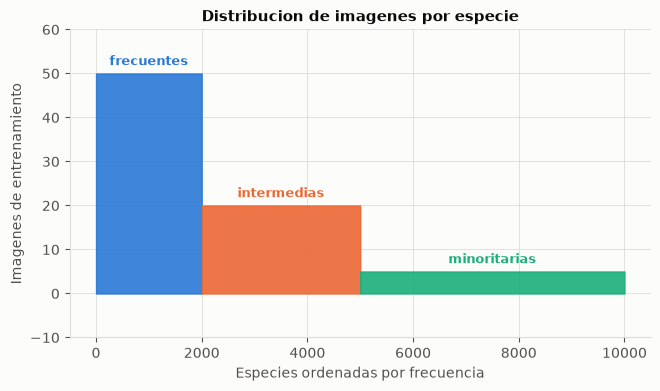

In [28]:
# Forma de la distribucion construida.
if requiere(INDEX_OK, "los indices Parquet",
            "scp -r <usuario>@khipu.utec.edu.pe:~/datasets/inat2021/index data/inat2021/"):
    from inat.data import make_scenario
    cfg_lt = DataConfig(scenario="longtail", **registry.LT_QUOTAS)
    esc_lt = make_scenario(PATHS, cfg_lt)
    print(f"escenario long-tail: {len(esc_lt.train):,} imagenes, {esc_lt.num_classes:,} especies")
    reparto = pd.Series(esc_lt.group_of_class).value_counts()
    resumen = pd.DataFrame({
        "especies": reparto,
        "img/especie": [esc_lt.class_counts[esc_lt.group_of_class == g].mean()
                        for g in reparto.index],
        "imagenes": [esc_lt.class_counts[esc_lt.group_of_class == g].sum()
                     for g in reparto.index],
    })
    display(resumen)
    print(f"razon de desbalance cabeza:cola = "
          f"{resumen.loc['head','img/especie'] / resumen.loc['tail','img/especie']:.1f}:1")
    plots.plot_class_distribution(esc_lt.class_counts, esc_lt.group_of_class,
                                  path=PATHS.figures / "21_longtail_dist.png")
    plt.show()

In [29]:
LT = analysis.longtail_summary(RESULTS)
if len(LT):
    vista = LT.copy()
    for c in [c for c in vista.columns if c.endswith(("recall", "f1", "top1", "head_tail"))]:
        vista[c] = (vista[c] * 100).round(2)
    display(vista)
    plots.plot_group_recall(LT, path=PATHS.figures / "22_longtail_grupos.png")
    plt.show()
else:
    print("Pendiente: fase 'longtail'.")

Pendiente: fase 'longtail'.


In [30]:
# Lectura central: cuanto cierra cada mitigacion la brecha cabeza-cola, y a que precio
# en las clases frecuentes.
if len(LT) and "brecha_head_tail" in LT.columns:
    base = LT[LT["exp_id"] == "L3"]
    if len(base):
        b = base.iloc[0]
        comp = LT[LT["exp_id"].isin(["L3", "L4", "L5", "L6"])].copy()
        comp["delta_tail"] = (comp["tail_recall"] - b["tail_recall"]) * 100
        comp["delta_head"] = (comp["head_recall"] - b["head_recall"]) * 100
        comp["delta_macroF1"] = (comp["macro_f1"] - b["macro_f1"]) * 100
        display(comp[["exp_id", "name", "delta_tail", "delta_head", "delta_macroF1",
                      "brecha_head_tail"]].round(2))

---
# Evaluación de los modelos

Con 10,000 especies el Accuracy agregado por sí solo es insuficiente: una clase mal
aprendida mueve el Top-1 en 0.01 puntos. Se reportan por tanto cuatro métricas con lecturas
distintas:

- **Top-1** — exactitud estricta.
- **Top-5** — útil en un escenario de asistencia a la identificación, donde proponer cinco
  candidatos es una salida válida.
- **Macro-F1** — promedia por clase, **sin ponderar por frecuencia**: es la métrica que
  revela si el modelo abandonó las especies raras.
- **Weighted-F1** — promedia ponderando por soporte.

**Una precisión sobre Weighted-F1 en este dataset.** El conjunto de validación de
iNaturalist 2021 tiene exactamente 10 imágenes por especie, de modo que todos los soportes
son iguales y **el Weighted-F1 coincide numéricamente con el Macro-F1 por construcción**.
Se reporta porque el enunciado lo pide, pero no aporta información adicional aquí; el
contraste informativo es el que hay entre **Top-1 y Macro-F1**. El Top-1 pondera cada
*imagen* por igual y el Macro-F1 cada *especie* por igual: cuando el modelo concentra sus
aciertos en un subconjunto de clases, el Top-1 se sostiene mientras el Macro-F1 cae.

Esto se mantiene también en el escenario long-tail, porque allí solo se submuestrea el
conjunto de **entrenamiento**: la validación sigue balanceada, que es justamente lo que
permite medir sin sesgo el rendimiento sobre las clases minoritarias.

In [31]:
if len(RESULTS):
    TABLA_FINAL = analysis.final_table(RESULTS)
    display(TABLA_FINAL)
    TABLA_FINAL.to_csv(PATHS.results / "tabla_final.csv", index=False)
    print(f"\nguardada en {PATHS.results / 'tabla_final.csv'}")

,ID,Modelo,Bloque,Arquitectura,Resolucion,Optimizador,LR,Augmentation,Preentrenado,Congelamiento,Escenario,Top-1,Top-5,Macro-F1,Weighted-F1,Entrenables (M),GPU-h,Epocas
0,A1,resnet50_scratch,arquitectura,resnet50,160,sgd_momentum,0.1000,rrc+flip,False,none,balanced,37.15,60.12,36.26,36.26,44.00,0.61,12
1,A2,efficientnet_b0_scratch,arquitectura,efficientnet_b0,160,sgd_momentum,0.1000,rrc+flip,False,none,balanced,33.97,56.65,32.83,32.83,16.82,0.53,12
2,A3,mobilenet_v3_large_scratch,arquitectura,mobilenet_v3_large,160,sgd_momentum,0.1000,rrc+flip,False,none,balanced,30.74,52.73,29.80,29.80,17.01,0.41,12
3,B1,mlp_32px,baseline,mlp,32,adam,0.0010,flip,False,none,balanced,1.95,5.77,1.36,1.36,18.65,0.58,10
4,B2,mlp_48px,baseline,mlp,48,adam,0.0010,flip,False,none,balanced,1.86,5.52,1.27,1.27,26.51,0.21,10
5,B3,mlp_64px,baseline,mlp,64,adam,0.0010,flip,False,none,balanced,1.77,5.28,1.18,1.18,37.52,0.22,10
6,B4,mlp_64px_sin_bn,baseline,mlp,64,adam,0.0010,flip,False,none,balanced,0.40,1.69,0.13,0.13,37.52,0.22,10
7,O1,resnet50_sgd,optimizacion,resnet50,160,sgd,0.1000,rrc+flip,False,none,balanced,11.88,26.84,10.10,10.10,44.00,0.59,12
8,O2,resnet50_sgd_momentum,optimizacion,resnet50,160,sgd_momentum,0.1000,rrc+flip,False,none,balanced,37.15,60.12,36.26,36.26,44.00,0.59,12
9,O3,resnet50_adam,optimizacion,resnet50,160,adam,0.0010,rrc+flip,False,none,balanced,37.75,60.72,36.93,36.93,44.00,0.60,12



guardada en /home/pedro.caycho/experiments/inat2021_proyecto1/results/tabla_final.csv


In [32]:
# Promedio sobre semillas donde hay mas de una: la dispersion acota que
# diferencias son interpretables.
if len(RESULTS):
    multi = analysis.aggregate_seeds(RESULTS)
    display(multi[multi["n_seeds"] > 1][
        ["exp_id", "name", "n_seeds", "top1_mean", "top1_std",
         "macro_f1_mean", "macro_f1_std"]].round(4))

,exp_id,name,n_seeds,top1_mean,top1_std,macro_f1_mean,macro_f1_std


mejor modelo: V3_verify_transfer_s42  (Top-1 = 58.40%)


,taxon,n_classes,recall,macro_f1
0,Agaricomycetes,1,0.900000,0.900000
1,Lecanoromycetes,1,0.900000,0.900000
2,Actinopterygii,1,0.800000,0.888889
3,Bivalvia,1,1.000000,0.869565
4,Reptilia,2,0.850000,0.775000
5,Insecta,11,0.636364,0.647050
6,Aves,9,0.677778,0.641011
7,Magnoliopsida,22,0.463636,0.418154
8,Liliopsida,2,0.300000,0.285256


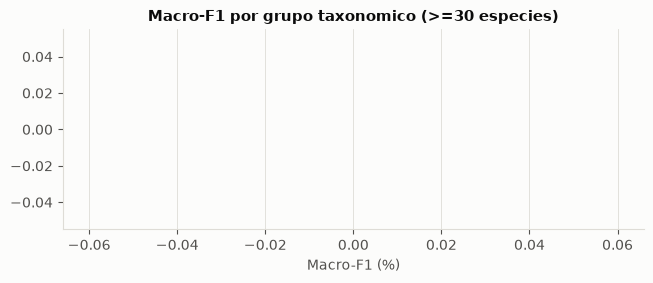

In [33]:
# Rendimiento por grupo taxonomico del mejor modelo.
if len(RESULTS):
    mejor = RESULTS.loc[RESULTS["top1"].idxmax()]
    print(f"mejor modelo: {mejor['run_name']}  (Top-1 = {mejor['top1']*100:.2f}%)")
    tax = analysis.taxon_summary(RESULTS, mejor["run_name"])
    if len(tax):
        display(tax.head(20))
        grandes = tax[tax["n_classes"] >= 30].assign(f1_pct=lambda d: d["macro_f1"] * 100)
        plots.plot_metric_bars(grandes, "taxon", "f1_pct",
                               "Macro-F1 por grupo taxonomico (>=30 especies)",
                               "Macro-F1 (%)", color_idx=2,
                               path=PATHS.figures / "23_por_taxon.png")
        plt.show()

---
# Análisis de errores

Se analiza el mejor modelo obtenido. El enunciado descarta explícitamente una matriz de
confusión de 10,000 × 10,000; lo que se busca son **patrones de error interpretables**.

Las preguntas que guían el análisis:

1. ¿Las especies confundidas pertenecen al mismo género?
2. ¿Existen grupos taxonómicos considerablemente más difíciles?
3. ¿Cómo se reparte la confianza entre aciertos y errores?
4. ¿Las clases minoritarias fallan de una forma **cualitativamente distinta**?

In [34]:
# Recalcula las predicciones del mejor modelo guardado. Requiere los pesos
# (results/models/) y el corpus; si falta alguno, el bloque queda pendiente.
import torch
from inat.config import ExperimentConfig, DataConfig, ModelConfig, OptimConfig, EarlyStopConfig
from inat.data import make_scenario, load_categories
from inat.models import build_model
from inat import errors

MODELOS = sorted((PATHS.results / "models").glob("*.pt")) if (PATHS.results / "models").exists() else []
PRED = None
escenario = None
CATS = None

if MODELOS and DATA_OK:
    disponibles = RESULTS[RESULTS["run_name"].isin(p.stem for p in MODELOS)]
    elegido = disponibles.loc[disponibles["top1"].idxmax(), "run_name"]
    blob = torch.load(PATHS.results / "models" / f"{elegido}.pt",
                      map_location="cpu", weights_only=False)
    cfg = ExperimentConfig(
        exp_id=blob["config"]["exp_id"], name=blob["config"]["name"],
        group=blob["config"]["group"], seed=blob["config"]["seed"],
        data=DataConfig(**blob["config"]["data"]), model=ModelConfig(**blob["config"]["model"]),
        optim=OptimConfig(**blob["config"]["optim"]),
        early_stop=EarlyStopConfig(**blob["config"]["early_stop"]))
    escenario = make_scenario(PATHS, cfg.data)
    modelo = build_model(cfg.model, escenario.num_classes, cfg.data.image_size)
    modelo.load_state_dict(blob["state_dict"])
    disp = torch.device("cuda" if torch.cuda.is_available() else "cpu")
    PRED = errors.collect_predictions(modelo, escenario, cfg, PATHS, disp)
    CATS = escenario.categories
    print(f"modelo analizado: {elegido}  ({len(PRED.targets):,} imagenes de validacion)")
    print(f"Top-1 recalculado: {PRED.correct.mean()*100:.2f}%")
else:
    print("Pendiente: se necesitan los pesos en results/models/ y el corpus.")

Pendiente: se necesitan los pesos en results/models/ y el corpus.


In [35]:
# 1. Pares de especies mas confundidos y su relacion taxonomica.
if PRED is not None:
    pares = errors.confusion_pairs(PRED, CATS, top=20)
    display(pares)
    print(f"\nde los 20 pares mas confundidos, {pares['mismo_genero'].sum()} comparten genero "
          f"y {pares['misma_familia'].sum()} comparten familia")

In [36]:
# 2. A que nivel taxonomico se queda el error.
if PRED is not None:
    perfil = errors.taxonomic_error_profile(PRED, CATS)
    display(perfil.assign(porcentaje=lambda d: (d["proporcion"] * 100).round(1)))
    plots.plot_metric_bars(
        perfil.assign(pct=perfil["proporcion"] * 100), "nivel", "pct",
        "Proporcion de errores que se queda dentro de cada nivel taxonomico",
        "% de los errores", color_idx=1, path=PATHS.figures / "24_errores_taxonomia.png")
    plt.show()

In [37]:
# 3. Confianza del modelo.
if PRED is not None:
    display(errors.confidence_analysis(PRED).round(2))
    plots.plot_confidence_histogram(PRED.confidence[PRED.correct],
                                    PRED.confidence[~PRED.correct],
                                    path=PATHS.figures / "25_confianza.png")
    plt.show()

In [38]:
# 4. Ejemplos cualitativos de cada tipo de prediccion.
if PRED is not None:
    for tipo, titulo in [
        ("correcta_alta", "Predicciones correctas con alta confianza"),
        ("correcta_baja", "Predicciones correctas con baja confianza"),
        ("incorrecta_alta", "Predicciones incorrectas con alta confianza"),
        ("atipica", "Imagenes atipicas (probabilidad minima a la clase real)"),
    ]:
        imgs, caps = errors.example_images(PRED, CATS, PATHS, tipo, n=6)
        plots.plot_image_grid(imgs, caps, ncols=6, title=titulo,
                              path=PATHS.figures / f"26_errores_{tipo}.png")
        plt.show()

In [39]:
# 5. Bloque de confusion de las clases con mas errores.
if PRED is not None:
    matriz, etiquetas = errors.confusion_block(PRED, CATS, n_classes=15)
    plots.plot_confusion_block(matriz, etiquetas,
                               path=PATHS.figures / "27_confusion.png")
    plt.show()

In [40]:
# 6. Tipo de error en las clases minoritarias (solo en el escenario long-tail).
if PRED is not None and getattr(escenario, "group_of_class", None) is not None:
    perfil_grupo = errors.group_error_profile(PRED, escenario.group_of_class)
    display(perfil_grupo.round(4))
    print("\n'prediccion_hacia_head' mide el sesgo del clasificador: que fraccion de los")
    print("errores de cada grupo cae en una especie frecuente.")

---
# Discusión

*(A completar con las cifras concretas una vez ejecutada la cadena de experimentos. La
estructura de la discusión es la siguiente.)*

**Sobre el preentrenamiento.** La comparación `T5` (desde cero) → `T0` (congelado) → `T4`
(completo) descompone el beneficio en dos partes separables: lo que aportan las
representaciones de ImageNet *tal cual*, y lo que aporta **adaptarlas**. Son cantidades
distintas y la literatura a menudo las confunde.

**Sobre el costo.** El fine-tuning completo es la condición más cara en las tres métricas
de costo medidas (horas de GPU, parámetros entrenables, memoria pico). La pregunta práctica
no es si gana, sino si la mejora justifica el gasto — y eso depende del punto de operación,
que es exactamente lo que la frontera de la figura 17 permite leer.

**Sobre el desbalance.** La separación L2/L3 permite afirmar cuánto del deterioro proviene
del desbalance y cuánto de tener menos datos. Las mitigaciones deben juzgarse por Macro-F1
y por el recall de la cola, no por Top-1: una estrategia que suba el Top-1 bajando el recall
de las minoritarias está yendo en la dirección contraria al objetivo.

---
# Limitaciones

1. **Un solo backbone en el bloque principal.** El barrido de descongelamiento se hizo con
   ResNet-50. La forma de la curva podría diferir en arquitecturas con otra organización de
   etapas (ConvNeXt, EfficientNet), por lo que las conclusiones sobre `k` óptimo no se
   extrapolan sin más.
2. **Presupuesto de épocas fijo.** Todas las condiciones recibieron el mismo número de
   épocas. El fine-tuning completo tiene más parámetros que ajustar y podría beneficiarse
   más de un presupuesto mayor; el resultado es válido *a presupuesto igual*, que es la
   comparación relevante para P2 pero no la única posible.
3. **Dos semillas, y solo en tres condiciones.** Suficiente para acotar la dispersión en los
   puntos sobre los que se apoyan las conclusiones, insuficiente para contrastes
   estadísticos formales.
4. **Validación usada para selección.** El learning rate y la época de parada se eligieron
   sobre validación. No hay un conjunto de test independiente en la distribución pública del
   dataset, de modo que las cifras absolutas tienen un sesgo optimista; las *comparaciones*
   entre condiciones, que es lo que las hipótesis afirman, no se ven afectadas porque el
   mismo procedimiento se aplicó a todas.
5. **Resolución reducida.** 160 px en la grilla exploratoria y 224 px en el bloque
   principal. Los rasgos diagnósticos más finos podrían requerir más resolución, de modo que
   las cifras absolutas son un piso.
6. **El escenario long-tail es sintético.** Reproduce la *forma* de un desbalance real, no
   un desbalance observado: la asignación a grupos es aleatoria y por tanto independiente de
   la rareza biológica real de cada especie.

---
# Conclusiones

*(A redactar sobre la evidencia experimental, respondiendo explícitamente a P1 y P2 y
declarando si H1 y H2 se sostienen o se refutan.)*

---
# Referencias

- Van Horn, G. et al. (2021). *Benchmarking Representation Learning for Natural World Image Collections*. CVPR.
- He, K., Zhang, X., Ren, S., Sun, J. (2016). *Deep Residual Learning for Image Recognition*. CVPR.
- Tan, M., Le, Q. (2019). *EfficientNet: Rethinking Model Scaling for Convolutional Neural Networks*. ICML.
- Howard, A. et al. (2019). *Searching for MobileNetV3*. ICCV.
- Yosinski, J., Clune, J., Bengio, Y., Lipson, H. (2014). *How transferable are features in deep neural networks?* NeurIPS.
- Kornblith, S., Shlens, J., Le, Q. (2019). *Do Better ImageNet Models Transfer Better?* CVPR.
- Cui, Y., Jia, M., Lin, T.-Y., Song, Y., Belongie, S. (2019). *Class-Balanced Loss Based on Effective Number of Samples*. CVPR.
- Lin, T.-Y., Goyal, P., Girshick, R., He, K., Dollár, P. (2017). *Focal Loss for Dense Object Detection*. ICCV.
- Loshchilov, I., Hutter, F. (2019). *Decoupled Weight Decay Regularization*. ICLR.
- Ioffe, S., Szegedy, C. (2015). *Batch Normalization: Accelerating Deep Network Training by Reducing Internal Covariate Shift*. ICML.